In [1]:
#Tahap 1: Load Dataset
# Impor library yang diperlukan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Baca file dataset_tugas1_preprocessing.csv ke dalam DataFrame
df = pd.read_csv('dataset_tugas1_preprocessing.csv')
df.head()


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


In [3]:
# Tahap 2: Eksplorasi Awal (EDA)

In [4]:
# Cek struktur dan tipe data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     str    
 1   Nama           99 non-null     str    
 2   Jenis_Kelamin  99 non-null     str    
 3   Prodi          99 non-null     str    
 4   Status         99 non-null     str    
 5   Nilai_Akhir    70 non-null     str    
 6   Tanggal_Ujian  99 non-null     str    
 7   Umur           90 non-null     float64
dtypes: float64(1), str(7)
memory usage: 10.8 KB


In [5]:
#Tampilkan jumlah nilai hilang per kolom
print("\njumlah nilai hilang perkolom:")
print(df.isnull().sum())



jumlah nilai hilang perkolom:
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64


In [6]:
# Sajikan statistik deskriptif
df.describe(include='all')

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
count,99,99,99,99,99,70,99,90.000000
unique,99,10,2,4,4,5,97,NaN
top,MH001,Eka,Laki-laki,Teknik Komputer,Cuti,C,2020/03/31,NaN
freq,1,15,50,28,29,17,2,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.366667
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.763963
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.000000


In [7]:
# Tahap 3: Menangani Missing Values

In [9]:
# Imputasi nilai kosong pada kolom Nilai_Akhir dan Umur dengan metode yang sesuai
# Nilai Akhir
modus_Nilai_Akhir=df['Nilai_Akhir'].mode()[0]
df['Nilai_Akhir']=df['Nilai_Akhir'].fillna(modus_Nilai_Akhir)
print (df)
print ("modus nilai akhir :",df['Nilai_Akhir'].mode())
# umur
df['Umur']=df['Umur'].fillna (df['Umur'].median())
print ("median  Umur :",df['Umur'].median())

       ID  Nama Jenis_Kelamin             Prodi Status Nilai_Akhir  \
0   MH001  Iwan     Laki-laki   Teknik Komputer  Aktif           C   
1   MH002   Eka     Perempuan   Teknik Komputer  Lulus           E   
2   MH003  Iwan     Laki-laki   Teknik Komputer  Aktif           C   
3   MH004   Eka     Perempuan   Teknik Komputer  Aktif           D   
4   MH005  Joko     Perempuan      Data Science  Aktif           C   
..    ...   ...           ...               ...    ...         ...   
94  MH095  Gita     Laki-laki   Teknik Komputer  Aktif           D   
95  MH096   Adi     Laki-laki  Sistem Informasi  Lulus           C   
96  MH097  Iwan     Laki-laki      Data Science  Lulus           D   
97  MH098   Eka     Perempuan      Data Science  Aktif           A   
98  MH099  Hana     Perempuan   Teknik Komputer     DO           C   

   Tanggal_Ujian  Umur  
0     13-04-2020   NaN  
1     2020/12/11  28.0  
2     2021/11/21  23.0  
3     2021/08/19  18.0  
4     2020/01/05  26.0  
..       

In [10]:
# Tahap 4: Normalisasi Format Tanggal

In [11]:
# Pastikan seluruh data pada kolom Tanggal_Ujian terkonversi ke format datetime
df['Tanggal_Ujian']=pd.to_datetime(df['Tanggal_Ujian'], format='mixed', dayfirst=True)
df['day']=df['Tanggal_Ujian'].dt.day
df['month']=df['Tanggal_Ujian'].dt.month
df['year']=df['Tanggal_Ujian'].dt.year
print (df)

       ID  Nama Jenis_Kelamin             Prodi Status Nilai_Akhir  \
0   MH001  Iwan     Laki-laki   Teknik Komputer  Aktif           C   
1   MH002   Eka     Perempuan   Teknik Komputer  Lulus           E   
2   MH003  Iwan     Laki-laki   Teknik Komputer  Aktif           C   
3   MH004   Eka     Perempuan   Teknik Komputer  Aktif           D   
4   MH005  Joko     Perempuan      Data Science  Aktif           C   
..    ...   ...           ...               ...    ...         ...   
94  MH095  Gita     Laki-laki   Teknik Komputer  Aktif           D   
95  MH096   Adi     Laki-laki  Sistem Informasi  Lulus           C   
96  MH097  Iwan     Laki-laki      Data Science  Lulus           D   
97  MH098   Eka     Perempuan      Data Science  Aktif           A   
98  MH099  Hana     Perempuan   Teknik Komputer     DO           C   

   Tanggal_Ujian  Umur  day  month  year  
0     2020-04-13  23.0   13      4  2020  
1     2020-11-12  28.0   12     11  2020  
2     2021-11-21  23.0   21   

In [12]:
# Tahap 5: Encoding Label

In [13]:
# Lakukan encoding (Label Encoding) pada kolom kategorikal: Nama, Jenis_Kelamin, Prodi, Status, Nilai_Akhir
from sklearn.preprocessing import LabelEncoder
label_encoder=LabelEncoder()
data ={'Kolom_Kategori': ['Nama','Jenis_Kelamin','prodi','Status','Nilai_Akhir']}
df=pd.DataFrame(data)
df['Kolom_Kategori_encoded']=label_encoder.fit_transform(df['Kolom_Kategori'])
print (df)

  Kolom_Kategori  Kolom_Kategori_encoded
0           Nama                       1
1  Jenis_Kelamin                       0
2          prodi                       4
3         Status                       3
4    Nilai_Akhir                       2


In [14]:
# Tahap 6: Split Data


In [22]:
df = pd.read_csv('dataset_tugas1_preprocessing.csv')
df.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


In [23]:
# Bagi data menjadi data latih dan data uji (80% - 20%)
from sklearn.model_selection import train_test_split
data_latih, data_uji=train_test_split(df,test_size=0.25, random_state=52)
print (F"Jumlah Data Latih (80%):{len(data_latih)}")
print (F"Jumlah Data Uji (20%):{len(data_uji)}")


Jumlah Data Latih (80%):74
Jumlah Data Uji (20%):25


In [24]:
# Tahap 7: Visualisasi

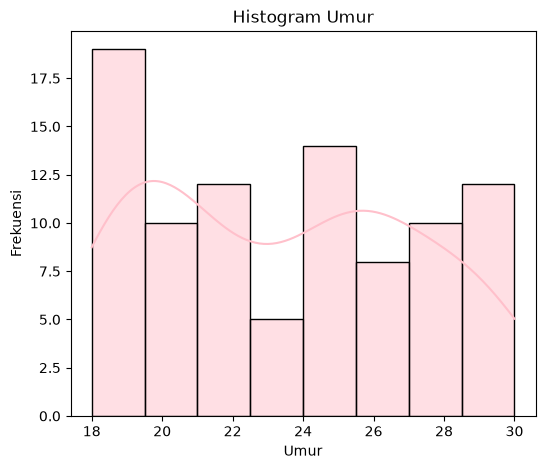

In [25]:
# Buat histogram untuk kolom Umur
plt.figure (figsize=(6,5))
sns.histplot(df['Umur'],kde=True,color='pink')
plt.title('Histogram Umur')
plt.xlabel('Umur')
plt.ylabel('Frekuensi')
plt.show()

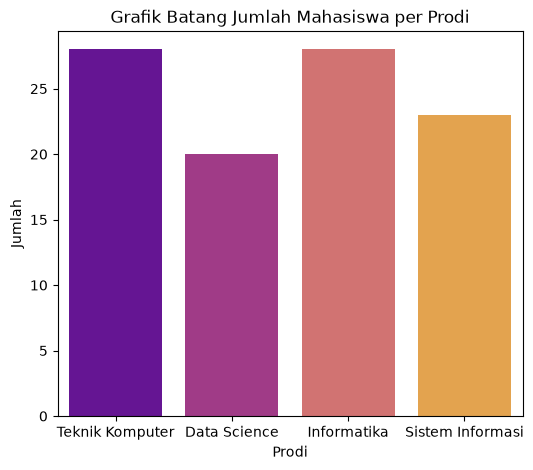

In [27]:
# Buat grafik batang jumlah mahasiswa per Prodi
plt.figure (figsize=(6,5))
sns.countplot(x='Prodi', data = df, hue='Prodi',palette='plasma', legend = False)
plt.title('Grafik Batang Jumlah Mahasiswa per Prodi')
plt.xlabel('Prodi')
plt.ylabel('Jumlah')
plt.show()